# 2026.10.12(월) 20h~

데이터 소스 = https://nlp.stanford.edu/projects/glove/

cf. claude --resume 7258f132-2c9a-45e5-96ee-79b97c015852

In [2]:
# ============================================================
# 1. 라이브러리와 기본 설정
# ============================================================
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Dropout, Bidirectional
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# 모델을 다시 실행할 때 이전 모델 상태 정리
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

max_words = 10000       # 사용할 인덱스/단어 범위: 0~9999
maxlen = 100            # 입력 문장의 최대 토큰 수
embedding_dim = 100     # GloVe 단어 벡터의 차원 = 임베딩 벡터의 크기 <- 100개의 실수

# 실제 GloVe 파일 위치에 맞게 수정
# glove_path = Path(r"D:\data_set\glove.6B\glove.6B.100d.txt")
glove_path = Path(r"../dataset/glove.6B/glove.6B.100d.txt")

if not glove_path.is_file():
    raise FileNotFoundError(
        f"GloVe 파일을 찾을 수 없습니다. 경로를 확인하세요: {glove_path}"
    )


# ============================================================
# 2. IMDB 데이터셋 로드 및 패딩
# ============================================================
# 특수 토큰: 0=패딩, 1=문장 시작, 2=미등록 단어
# 일반 단어의 번호는 원래 사전 번호에 3을 더해 사용
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=max_words,
    start_char=1,
    oov_char=2,
    index_from=3
)

# 짧은 문장은 뒤에 0을 채움
# 긴 문장은 기존 코드와 같이 앞부분을 잘라 마지막 maxlen개를 유지
x_train = pad_sequences(
    x_train,
    maxlen=maxlen,
    padding="post",
    truncating="pre"
)

x_test = pad_sequences(
    x_test,
    maxlen=maxlen,
    padding="post",
    truncating="pre"
)

y_train = np.asarray(y_train, dtype="float32")
y_test = np.asarray(y_test, dtype="float32")

print("학습 데이터:", x_train.shape)
print("테스트 데이터:", x_test.shape)


# ============================================================
# 3. GloVe 단어 벡터 로드
# ============================================================
embeddings_index = {} # dictionary

print("\nGloVe 단어 벡터를 불러옵니다.")

with glove_path.open(encoding="utf-8") as f:
    for line in f: # 파일을 line별로 읽음
        values = line.split()

        if not values:
            continue

        word = values[0]
        vector = np.asarray(values[1:], dtype="float32")

        # 설정한 차원과 파일의 벡터 차원이 일치하는지 확인
        if vector.shape != (embedding_dim,):
            raise ValueError(
                f"'{word}'의 벡터 차원이 {embedding_dim}과 다릅니다. "
                "GloVe 파일 종류를 확인하세요."
            )

        embeddings_index[word] = vector

print(f"불러온 단어 벡터 수: {len(embeddings_index):,}개")

# 특정 단어의 벡터 확인
example_word = "the"
example_vector = embeddings_index.get(example_word)

if example_vector is not None:
    print(f"\n'{example_word}'의 벡터 크기:", example_vector.shape)
    print("앞의 10개 값:", example_vector[:10])
else:
    print(f"'{example_word}'의 벡터를 찾을 수 없습니다.")

학습 데이터: (25000, 100)
테스트 데이터: (25000, 100)

GloVe 단어 벡터를 불러옵니다.
불러온 단어 벡터 수: 400,000개

'the'의 벡터 크기: (100,)
앞의 10개 값: [-0.038194 -0.24487   0.72812  -0.39961   0.083172  0.043953 -0.39141
  0.3344   -0.57545   0.087459]


In [3]:
# ============================================================
# 4. IMDB 단어 번호와 GloVe 벡터 연결
# ============================================================
# 원래 IMDB 사전: 단어 → 1부터 시작하는 번호
word_index = imdb.get_word_index()

# 학습 데이터에서 사용하는 실제 단어 번호
imdb_word_index = {
    word: original_index + 3
    for word, original_index in word_index.items()
}

embedding_matrix = np.zeros(
    (max_words, embedding_dim),
    dtype="float32"
)

matched_count = 0
candidate_count = 0

for word, actual_index in imdb_word_index.items():
    if actual_index >= max_words:
        continue

    candidate_count += 1
    vector = embeddings_index.get(word)

    if vector is not None:
        embedding_matrix[actual_index] = vector
        matched_count += 1

# 0~3번 특수 토큰과 GloVe에 없는 단어는 0 벡터로 유지
print("\n임베딩 행렬 크기:", embedding_matrix.shape)
print("사용 범위의 일반 단어 수:", candidate_count)
print("GloVe 연결 단어 수:", matched_count)
print("GloVe에 없는 단어 수:", candidate_count - matched_count)

# 'the'의 학습 데이터 번호와 연결된 벡터 확인
the_index = imdb_word_index.get("the")

if (
    the_index is not None
    and the_index < max_words
    and example_vector is not None
):
    assert np.allclose(
        embedding_matrix[the_index],
        example_vector
    )
    print(f"'the' 연결 확인: 인덱스 {the_index}")

# 이후에는 임베딩 행렬만 사용하므로 큰 원본 사전은 메모리에서 해제
del embeddings_index


임베딩 행렬 크기: (10000, 100)
사용 범위의 일반 단어 수: 9996
GloVe 연결 단어 수: 9793
GloVe에 없는 단어 수: 203
'the' 연결 확인: 인덱스 4


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 100, 128)       │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,187,457 (4.53 MB)

 Trainable params: 187,457 (732.25 KB)

 Non-trainable params: 1,000,000 (3.81 MB)

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 359s 2s/step - accuracy: 0.5646 - loss: 0.6799 - val_accuracy: 0.6750 - val_loss: 0.6237
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 207s 1s/step - accuracy: 0.7208 - loss: 0.5685 - val_accuracy: 0.7406 - val_loss: 0.5352
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 193s 875ms/step - accuracy: 0.7552 - loss: 0.5222 - val_accuracy: 0.7508 - val_loss: 0.5109
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 132s 844ms/step - accuracy: 0.7654 - loss: 0.5010 - val_accuracy: 0.7572 - val_loss: 0.4994
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 129s 759ms/step - accuracy: 0.7723 - loss: 0.4880 - val_accuracy: 0.7656 - val_loss: 0.4861
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 120s 763ms/step - accuracy: 0.7783 - loss: 0.4768 - val_accuracy: 0.7698 - val_loss: 0.4814
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 118s 754ms/step - accuracy: 0.7854 - loss: 0.4684 - val_accuracy: 0.7720 - val_loss: 0.4683
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 119s 756ms/step - accuracy: 0.7879 - loss:

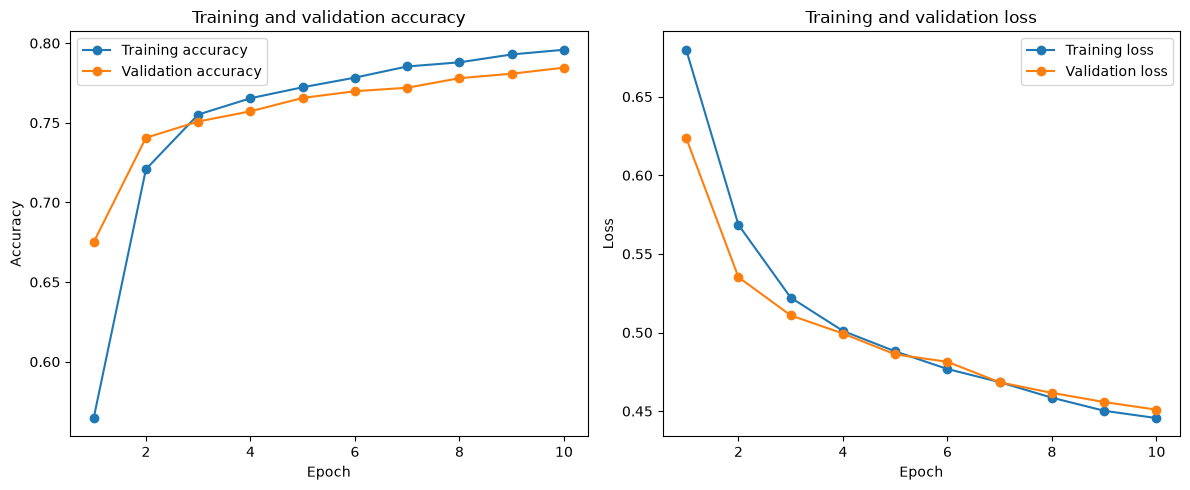

In [4]:
# ============================================================
# 5. 모델 구성 및 학습
# ============================================================
model = Sequential([
    Input(shape=(maxlen,), dtype="int32"),

    Embedding(
        input_dim=max_words,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False,   # 사전 학습한 GloVe 벡터 고정, embedding 설정에서 중요! 여기서 학습할 때 이 값은 바뀌지/학습되지 않도록 함
        mask_zero=True    # 0번 패딩 위치를 무시
    ),

    # 문장/단어 위치/순서에 대한 것도 학습
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.5),

    Bidirectional(LSTM(64)),
    # -----------

    Dense(32, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# 학습 데이터의 20%를 검증용으로 사용
# x_test, y_test는 최종 평가까지 사용하지 않음
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping],
    shuffle=True
)


# ============================================================
# 6. 최종 테스트 평가 및 학습 그래프
# ============================================================
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    batch_size=128,
    verbose=0
)

print(f"\n테스트 손실: {test_loss:.4f}")
print(f"테스트 정확도: {test_accuracy:.4f}")

epochs = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    epochs,
    history.history["accuracy"],
    "o-",
    label="Training accuracy"
)
plt.plot(
    epochs,
    history.history["val_accuracy"],
    "o-",
    label="Validation accuracy"
)
plt.title("Training and validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    epochs,
    history.history["loss"],
    "o-",
    label="Training loss"
)
plt.plot(
    epochs,
    history.history["val_loss"],
    "o-",
    label="Validation loss"
)
plt.title("Training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# 7. 새로운 문장 전처리
# ============================================================
# 새 문장으로 fit_on_texts()를 실행하지 않음
# 학습할 때 사용한 IMDB 단어 번호를 그대로 연결
tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<UNK>"
)

tokenizer.word_index = imdb_word_index.copy()
tokenizer.word_index["<UNK>"] = 2


def preprocess_texts(texts):
    """새 문장을 IMDB 단어 번호로 변환한 뒤 패딩합니다."""

    # 없는 단어와 사용 범위를 벗어난 단어는 2(<UNK>)로 처리
    sequences = tokenizer.texts_to_sequences(texts)

    # 학습 데이터와 동일하게 시작 토큰 추가
    sequences = [[1] + sequence for sequence in sequences]

    # 학습·테스트 데이터와 같은 패딩 및 자르기 방식 사용
    padded = pad_sequences(
        sequences,
        maxlen=maxlen,
        padding="post",
        truncating="pre"
    )

    return padded


# ============================================================
# 8. 새로운 문장의 감정 예측
# ============================================================
test_texts = [
    "I hated this movie. It was terrible and the acting was horrible.",

    "This was the worst film I have ever seen. Not worth the time.",

    "I loved this movie. It was fantastic and the acting was great.",

    "This was the best film I have seen in a long time. Totally worth it.",

    "I had high hopes for this movie, but it was a complete letdown. "
    "The storyline was incredibly dull, and the pacing was excruciatingly slow. "
    "The characters lacked depth, making it hard to care about their fates. "
    "Overall, a waste of time.",

    "This film was a disaster from start to finish. "
    "The dialogue was cringe-worthy, and the special effects looked outdated. "
    "I couldn't believe how poorly executed the entire production was. "
    "Definitely one to avoid.",

    "What an amazing film! The plot was deeply engaging, "
    "keeping me on the edge of my seat throughout. "
    "The actors delivered powerful performances that brought the story to life. "
    "This movie is a must-watch for everyone.",

    "I was thoroughly impressed by this film. "
    "The cinematography was stunning, capturing the beauty of every scene. "
    "The story was heartwarming and inspiring, "
    "and the music perfectly complemented the mood. "
    "An outstanding cinematic experience."
]

test_data = preprocess_texts(test_texts)

print("\n새 문장 입력 크기:", test_data.shape)
print("첫 문장의 입력 번호:", test_data[0, :20])

predictions = model.predict(test_data, verbose=0)

for text, prediction in zip(test_texts, predictions):
    score = float(prediction[0])
    sentiment = "긍정" if score >= 0.5 else "부정"

    print("\n문장:", text)
    print("예측 결과:", sentiment)
    print(f"긍정 점수: {score:.4f}")


새 문장 입력 크기: (8, 100)
첫 문장의 입력 번호: [   1   13 1800   14   20   12   16  394    5    4  116   16  527    0
    0    0    0    0    0    0]

문장: I hated this movie. It was terrible and the acting was horrible.
예측 결과: 부정
긍정 점수: 0.0904

문장: This was the worst film I have ever seen. Not worth the time.
예측 결과: 부정
긍정 점수: 0.3836

문장: I loved this movie. It was fantastic and the acting was great.
예측 결과: 긍정
긍정 점수: 0.9410

문장: This was the best film I have seen in a long time. Totally worth it.
예측 결과: 긍정
긍정 점수: 0.5479

문장: I had high hopes for this movie, but it was a complete letdown. The storyline was incredibly dull, and the pacing was excruciatingly slow. The characters lacked depth, making it hard to care about their fates. Overall, a waste of time.
예측 결과: 부정
긍정 점수: 0.0248

문장: This film was a disaster from start to finish. The dialogue was cringe-worthy, and the special effects looked outdated. I couldn't believe how poorly executed the entire production was. Definitely one to avoid.
예측 결과: